# Import Statements

In [3]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from sklearn.metrics import confusion_matrix
from datasets import load_dataset
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report

# Dataset Exploration

In [4]:
ds = load_dataset("Sp1786/multiclass-sentiment-analysis-dataset")

README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31232 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5205 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5206 [00:00<?, ? examples/s]

In [5]:
print(ds)
print(ds["train"].column_names)
print(ds["train"].features)
print("Training Samples : ", len(ds["train"]))
print("Validation Samples : ", len(ds["validation"]))
print("Testing Samples : ", len(ds["test"]))

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 31232
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5205
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5206
    })
})
['id', 'text', 'label', 'sentiment']
{'id': Value('int64'), 'text': Value('string'), 'label': Value('int64'), 'sentiment': Value('string')}
Training Samples :  31232
Validation Samples :  5205
Testing Samples :  5206


In [6]:
for i in range(5):
    print(ds["train"][i])

{'id': 9536, 'text': 'Cooking microwave pizzas, yummy', 'label': 2, 'sentiment': 'positive'}
{'id': 6135, 'text': 'Any plans of allowing sub tasks to show up in the widget?', 'label': 1, 'sentiment': 'neutral'}
{'id': 17697, 'text': " I love the humor, I just reworded it. Like saying 'group therapy' instead`a 'gang banging'. Keeps my moms off my back.   Hahaha", 'label': 2, 'sentiment': 'positive'}
{'id': 14182, 'text': ' naw idk what ur talkin about', 'label': 1, 'sentiment': 'neutral'}
{'id': 17840, 'text': ' That sucks to hear. I hate days like that', 'label': 0, 'sentiment': 'negative'}


# Cleaning

In [7]:
train_df = ds["train"].to_pandas().dropna(subset = ["text", "label"])
val_df = ds["validation"].to_pandas().dropna(subset=["text", "label"])
test_df = ds["test"].to_pandas().dropna(subset=["text", "label"])
y_train = train_df["label"].astype(int).values
y_val = val_df["label"].astype(int).values
y_test = test_df["label"].astype(int).values

# Vectorization

In [8]:
MAX_WORDS = 20000
MAX_LEN = 100

vectorizer = layers.TextVectorization(max_tokens=MAX_WORDS,
                                      output_sequence_length=MAX_LEN)
vectorizer.adapt(train_df["text"].astype(str).values)

def to_numbers(texts):
    return vectorizer(tf.constant(texts.astype(str).values)).numpy()

X_train = to_numbers(train_df["text"])
X_val = to_numbers(val_df["text"])
X_test = to_numbers(test_df["text"])

# Model Building Function

In [29]:
def build_model(model_type, units, dropout, learning_rate):
    model = models.Sequential()
    model.add(layers.Input(shape=(MAX_LEN,)))

    if model_type == "NN":
        model.add(layers.Embedding(MAX_WORDS, 64))
        model.add(layers.Flatten())
        model.add(layers.Dense(units, activation="relu"))
        model.add(layers.Dropout(dropout))
    else:
        model.add(layers.Embedding(MAX_WORDS, 64, mask_zero=True))
        if model_type == "RNN":
            model.add(layers.SimpleRNN(units))
        elif model_type == "LSTM":
            model.add(layers.Bidirectional(layers.LSTM(units)))
        elif model_type == "GRU":
            model.add(layers.Bidirectional(layers.GRU(units)))

    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(3, activation="softmax"))

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# Hyperparameter Tuning and Model Training

In [10]:
units_list = [64, 128]
dropout_list = [0.2, 0.3]
lr_list = [0.001, 0.0005]

results = []
best_models = {}
best_scores = {}

In [31]:
model_type = "NN"
best_scores[model_type] = 0

for units, dropout, lr in itertools.product(units_list, dropout_list, lr_list):
    print(f"\nTraining {model_type} | units={units}, dropout={dropout}, lr={lr}")
    model = build_model(model_type, units, dropout, lr)
    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=5, batch_size=64, verbose=0)
    val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
    print("Validation accuracy:", round(val_acc, 4))
    results.append({"model": model_type, "units": units, "dropout": dropout, "learning_rate": lr, "val_accuracy": val_acc})

    if val_acc > best_scores[model_type]:
        best_scores[model_type] = val_acc
        best_models[model_type] = model


Training NN | units=64, dropout=0.2, lr=0.001
Validation accuracy: 0.6068

Training NN | units=64, dropout=0.2, lr=0.0005
Validation accuracy: 0.6295

Training NN | units=64, dropout=0.3, lr=0.001
Validation accuracy: 0.613

Training NN | units=64, dropout=0.3, lr=0.0005
Validation accuracy: 0.627

Training NN | units=128, dropout=0.2, lr=0.001
Validation accuracy: 0.6116

Training NN | units=128, dropout=0.2, lr=0.0005
Validation accuracy: 0.6238

Training NN | units=128, dropout=0.3, lr=0.001
Validation accuracy: 0.6116

Training NN | units=128, dropout=0.3, lr=0.0005
Validation accuracy: 0.6234


In [12]:
model_type = "RNN"
best_scores[model_type] = 0

for units, dropout, lr in itertools.product(units_list, dropout_list, lr_list):
    print(f"\nTraining {model_type} | units={units}, dropout={dropout}, lr={lr}")
    model = build_model(model_type, units, dropout, lr)
    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=5, batch_size=64, verbose=1)
    val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
    print("Validation accuracy:", round(val_acc, 4))
    results.append({"model": model_type, "units": units, "dropout": dropout, "learning_rate": lr, "val_accuracy": val_acc})

    if val_acc > best_scores[model_type]:
        best_scores[model_type] = val_acc
        best_models[model_type] = model


Training RNN | units=64, dropout=0.2, lr=0.001
Epoch 1/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.5824 - loss: 0.8902 - val_accuracy: 0.6501 - val_loss: 0.7862
Epoch 2/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.7405 - loss: 0.6448 - val_accuracy: 0.6427 - val_loss: 0.8081
Epoch 3/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8451 - loss: 0.4236 - val_accuracy: 0.6234 - val_loss: 0.9455
Epoch 4/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9136 - loss: 0.2518 - val_accuracy: 0.6042 - val_loss: 1.1664
Epoch 5/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9468 - loss: 0.1613 - val_accuracy: 0.5910 - val_loss: 1.4169
Validation accuracy: 0.591

Training RNN | units=64, dropout=0.2, lr=0.0005
Epoch 1/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.5584 - loss: 0.9207 - val_accuracy: 0.6469 - val_loss: 0.8084
Epoch 2/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7231 - loss: 0.6843 - val_accuracy: 0.65

In [15]:
train_mask = X_train.sum(axis=1) > 0
val_mask = X_val.sum(axis=1) > 0
test_mask = X_test.sum(axis=1) > 0

print("Removed rows (train, val, test):", (~train_mask).sum(), (~val_mask).sum(), (~test_mask).sum())

X_train, y_train = X_train[train_mask], y_train[train_mask]
X_val, y_val = X_val[val_mask], y_val[val_mask]
X_test, y_test = X_test[test_mask], y_test[test_mask]

Removed rows (train, val, test): 1 1 0


In [16]:
model_type = "LSTM"
best_scores[model_type] = 0

for units, dropout, lr in itertools.product(units_list, dropout_list, lr_list):
    print(f"\nTraining {model_type} | units={units}, dropout={dropout}, lr={lr}")
    model = build_model(model_type, units, dropout, lr)
    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=5, batch_size=64, verbose=1)
    val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
    print("Validation accuracy:", round(val_acc, 4))
    results.append({"model": model_type, "units": units, "dropout": dropout, "learning_rate": lr, "val_accuracy": val_acc})

    if val_acc > best_scores[model_type]:
        best_scores[model_type] = val_acc
        best_models[model_type] = model


Training LSTM | units=64, dropout=0.2, lr=0.001
Epoch 1/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.6160 - loss: 0.8292 - val_accuracy: 0.6756 - val_loss: 0.7376
Epoch 2/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.7415 - loss: 0.6237 - val_accuracy: 0.6710 - val_loss: 0.7457
Epoch 3/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.8031 - loss: 0.5031 - val_accuracy: 0.6572 - val_loss: 0.8024
Epoch 4/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.8496 - loss: 0.3987 - val_accuracy: 0.6591 - val_loss: 0.9674
Epoch 5/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.8883 - loss: 0.3059 - val_accuracy: 0.6447 - val_loss: 1.0281
Validation accuracy: 0.6447

Training LSTM | units=64, dropout=0.2, lr=0.0005
Epoch 1/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.5943 - loss: 0.8714 - val_accuracy: 0.6666 - val_loss: 0.7507
Epoch 2/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.7291 - loss: 0.6547 - val_accuracy: 

In [17]:
model_type = "GRU"
best_scores[model_type] = 0

for units, dropout, lr in itertools.product(units_list, dropout_list, lr_list):
    print(f"\nTraining {model_type} | units={units}, dropout={dropout}, lr={lr}")
    model = build_model(model_type, units, dropout, lr)
    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=5, batch_size=64, verbose=1)
    val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
    print("Validation accuracy:", round(val_acc, 4))
    results.append({"model": model_type, "units": units, "dropout": dropout, "learning_rate": lr, "val_accuracy": val_acc})

    if val_acc > best_scores[model_type]:
        best_scores[model_type] = val_acc
        best_models[model_type] = model


Training GRU | units=64, dropout=0.2, lr=0.001
Epoch 1/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6146 - loss: 0.8312 - val_accuracy: 0.6752 - val_loss: 0.7382
Epoch 2/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.7467 - loss: 0.6140 - val_accuracy: 0.6764 - val_loss: 0.7562
Epoch 3/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.8180 - loss: 0.4711 - val_accuracy: 0.6458 - val_loss: 0.8454
Epoch 4/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8670 - loss: 0.3533 - val_accuracy: 0.6412 - val_loss: 0.9623
Epoch 5/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9047 - loss: 0.2654 - val_accuracy: 0.6311 - val_loss: 1.1255
Validation accuracy: 0.6311

Training GRU | units=64, dropout=0.2, lr=0.0005
Epoch 1/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.5873 - loss: 0.8728 - val_accuracy: 0.6631 - val_loss: 0.7519
Epoch 2/5
488/488 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.7273 - loss: 0.6521 - val_accuracy: 0.66

In [38]:
results_df = pd.DataFrame(results)
final = []
model_types = ["NN", "RNN", "LSTM", "GRU"]
for model_type in model_types:
    rows = results_df[results_df["model"] == model_type]
    best_row = rows.loc[rows["val_accuracy"].idxmax()]
    test_loss, test_acc = best_models[model_type].evaluate(X_test, y_test, verbose=0)
    final.append({"model": model_type, "best_units": best_row["units"], "best_dropout": best_row["dropout"], "best_lr": best_row["learning_rate"], "val_accuracy": best_row["val_accuracy"], "test_accuracy": test_acc})

final_df = pd.DataFrame(final).sort_values("test_accuracy", ascending=False)
print("\nFinal comparison:")
print(final_df)


Final comparison:
  model  best_units  best_dropout  best_lr  val_accuracy  test_accuracy
2  LSTM          64           0.3   0.0005      0.654881       0.652450
3   GRU         128           0.3   0.0010      0.654881       0.639962
0    NN         128           0.3   0.0010      0.676979       0.631124
1   RNN         128           0.2   0.0005      0.621710       0.628050


# Evaluation of Best Model

In [33]:
best = final_df.iloc[0]
print("\nBEST MODEL:", best["model"])
print("Units:", best["best_units"])
print("Dropout:", best["best_dropout"])
print("Learning rate:", best["best_lr"])
print("Test accuracy:", round(best["test_accuracy"], 4))

pred = np.argmax(best_models[best["model"]].predict(X_test), axis=1)
print(classification_report(y_test, pred, target_names=["negative", "neutral", "positive"]))


BEST MODEL: LSTM
Units: 64
Dropout: 0.3
Learning rate: 0.0005
Test accuracy: 0.6524
163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
              precision    recall  f1-score   support

    negative       0.66      0.64      0.65      1546
     neutral       0.59      0.58      0.58      1929
    positive       0.71      0.75      0.73      1730

    accuracy                           0.65      5205
   macro avg       0.65      0.65      0.65      5205
weighted avg       0.65      0.65      0.65      5205



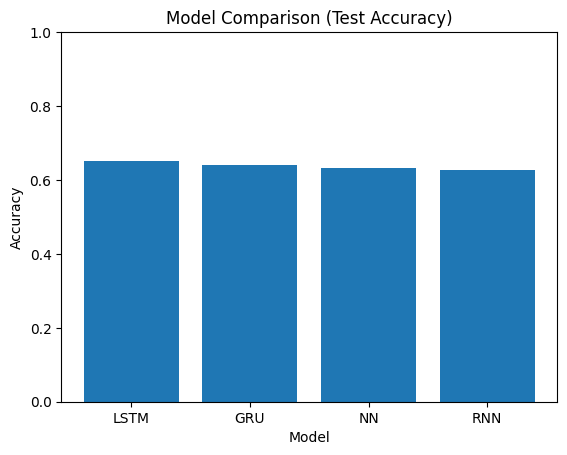

In [34]:
plt.bar(final_df["model"], final_df["test_accuracy"])
plt.title("Model Comparison (Test Accuracy)")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


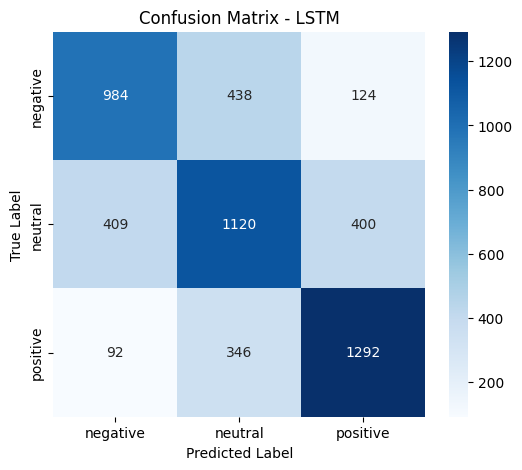

In [35]:
best_name = best["model"]
best_model = best_models[best_name]
pred = np.argmax(best_model.predict(X_test), axis = 1)
cm = confusion_matrix(y_test, pred)
class_names = ["negative","neutral", "positive"]
plt.figure(figsize = (6, 5))
sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues", xticklabels = class_names, yticklabels  = class_names)
plt.title("Confusion Matrix - " + best_name)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()